# Geodesic LTP deformation and stabilizer entropy

Interpolate from the computational stabilizer state to a bundled SIC fiducial,
then compare exact WH reference matrices with finite-shot local Cirq simulations.


Run with the repository installed (`pip install -e '.[notebooks]'`). The defaults
retain the original 100 interpolation points and 50,000 shots **per prepared
orbit state**. Outputs go under `artifacts/geodesic_ltp/` in the repository.

In [2]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cirq_sic.analysis import stabilizer_renyi_entropy
from cirq_sic.measurements import build_measurement_circuit, wh_measurement
from cirq_sic.sics import SIC_P, load_sic_fiducial
from cirq_sic.utils import geodesic_interpolator
from cirq_sic.workflow import CircuitSpec, Experiment, ExperimentResult

# Support launching from the repository root or this notebook's directory.
repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "cirq_sic").is_dir() and (p / "pyproject.toml").is_file()),
    None,
)
output_dir = (repo_root or Path.cwd()) / "artifacts" / "geodesic_ltp"
image_dir = output_dir / "img"
image_dir.mkdir(parents=True, exist_ok=True)

d = 2
n_shots = 50_000
seed = 2026
T = np.linspace(0, 1, 100)
alpha = 2
alphas = [2, 3, 4, 5]

psi_stab = np.eye(d, dtype=complex)[0]
psi_sic = load_sic_fiducial(d)
interpolation = geodesic_interpolator(psi_stab, psi_sic)
fiducials = interpolation(T)

## Reference-device circuits

For each fiducial, prepare every normalized WH orbit state and measure its WH
POVM. Columns index prepared states and rows index outcomes:

$$P_{ij}=\operatorname{Tr}(E_i\sigma_j)
=\frac{1}{d}|\langle\psi_i|\psi_j\rangle|^2.$$

We build the reference battery directly because the stabilizer endpoint is not
informationally complete; the tomography and sky/ground builders correctly
reject that endpoint. The general measurement circuit builder supports it.

In [3]:
measurements = [wh_measurement(fiducial) for fiducial in fiducials]
specs = []
for i, measurement in enumerate(measurements):
    for j, state in enumerate(measurement.states.T):
        built = build_measurement_circuit(measurement, state)
        specs.append(CircuitSpec(
            name=f"reference/{i}/{j}",
            circuit=built.circuit,
            qubit_order=built.qubit_order,
            measured_qubits=built.measured_qubits,
            key=built.measurement_key,
            num_outcomes=measurement.num_outcomes,
            metadata={"t": float(T[i]), "prepared_outcome": j},
        ))

experiment = Experiment(
    specs,
    name="geodesic_wh_reference",
    metadata={"dimension": d, "n_shots": n_shots, "seed": seed},
    arrays={"T": T, "fiducials": fiducials},
)
print(f"Built {len(experiment.circuits)} circuits for {len(T)} fiducials.")

Built 400 circuits for 100 fiducials.


In [4]:
exact_result = experiment.simulate()
sampled_result = experiment.run(repetitions=n_shots, seed=seed)

# Save the circuit specification and its bound results using the current API.
experiment.save(output_dir / "experiment.json")
exact_result.save(output_dir / "exact_result.json")
sampled_result.save(output_dir / "sampled_result.json")

In [6]:
def reference_matrices(result):
    matrices = []
    for i in range(len(T)):
        columns = [result[f"reference/{i}/{j}"] for j in range(d**2)]
        if any(column.leakage > 1e-8 for column in columns):
            raise ValueError("Reference readout has probability in padded outcomes.")
        matrices.append(np.column_stack([column.valid for column in columns]))
    return np.asarray(matrices)

P_t = reference_matrices(sampled_result)
exact_P_t = reference_matrices(exact_result)
analytic_P_t = np.asarray([
    np.abs(m.states.conj().T @ m.states)**2 / d for m in measurements
])

# Independent checks of circuit readout, endpoint rays, and SIC convention.
np.testing.assert_allclose(exact_P_t, analytic_P_t, atol=1e-10)
np.testing.assert_allclose(P_t.sum(axis=1), 1, atol=1e-10)
np.testing.assert_allclose(fiducials[0], psi_stab, atol=1e-12)
assert np.isclose(abs(np.vdot(fiducials[-1], psi_sic)), 1)
np.testing.assert_allclose(exact_P_t[-1], SIC_P(d), atol=1e-8)

# Check that the current persistence format preserves the observed counts.
reloaded_result = ExperimentResult.load(output_dir / "sampled_result.json")
np.testing.assert_array_equal(reference_matrices(reloaded_result), P_t)
print("Exact circuits agree with analytic overlaps; endpoints and saved results pass.")

Exact circuits agree with analytic overlaps; endpoints and saved results pass.


## Diagnostics

We retain the original natural-log convention (entropy in nats):
$$M_\alpha=\frac{\log\sum_i P_{i0}^{\alpha}}{1-\alpha}-\log d,
\qquad Q=\|P^+-I\|_F.$$
For these pure fiducials, the first reference column is the cyclic-WH
characteristic distribution. At $d=2$ its entropy is the usual qubit stabilizer
Rényi entropy. For larger dimensions this uses the cyclic WH structure, which
need not coincide with a tensor-product Pauli structure.

The Moore--Penrose pseudoinverse $P^+$ preserves the original notebook's
convention. At a rank-deficient point it is **not** an inverse Born-rule
transform. In particular, the value at $t=0$ is finite even though the inverse
for nearby informationally complete points becomes unbounded. Finite-shot
noise can also strongly perturb this diagnostic near singular points.

In [7]:
def calculate_magic(P, order):
    probabilities = np.asarray(P)[..., :, 0]
    return np.log(np.sum(probabilities**order, axis=-1)) / (1-order) - np.log(d)


def calculate_ltp_deformation(P):
    return np.linalg.norm(np.linalg.pinv(P) - np.eye(d**2), axis=(-2, -1))


def sic_entropy(order):
    return np.log((1 + (d-1)*(d+1)**(1-order)) / d) / (1-order)


magic_t = calculate_magic(P_t, alpha)
exact_magic_t = calculate_magic(exact_P_t, alpha)
quantumness_t = calculate_ltp_deformation(P_t)
exact_quantumness_t = calculate_ltp_deformation(exact_P_t)
max_magic = sic_entropy(alpha)
sic_quantumness = calculate_ltp_deformation(SIC_P(d))

# Cross-check the entropy against the library's state-based implementation.
for order in alphas:
    state_entropies = [
        stabilizer_renyi_entropy(state, alpha=order, basis="wh", base=np.e)
        for state in fiducials
    ]
    np.testing.assert_allclose(
        calculate_magic(exact_P_t, order), state_entropies, atol=1e-10,
    )
np.testing.assert_allclose(exact_magic_t[0], 0, atol=1e-10)
np.testing.assert_allclose(exact_magic_t[-1], max_magic, atol=1e-8)
np.testing.assert_allclose(exact_quantumness_t[-1], sic_quantumness, atol=1e-8)
print(f"SIC endpoint: M_{alpha} = {max_magic:.6f} nats; Q = {sic_quantumness:.6f}")
print("Exact reference ranks at endpoints:", np.linalg.matrix_rank(exact_P_t[[0, -1]]))

SIC endpoint: M_2 = 0.405465 nats; Q = 3.464102
Exact reference ranks at endpoints: [2 4]


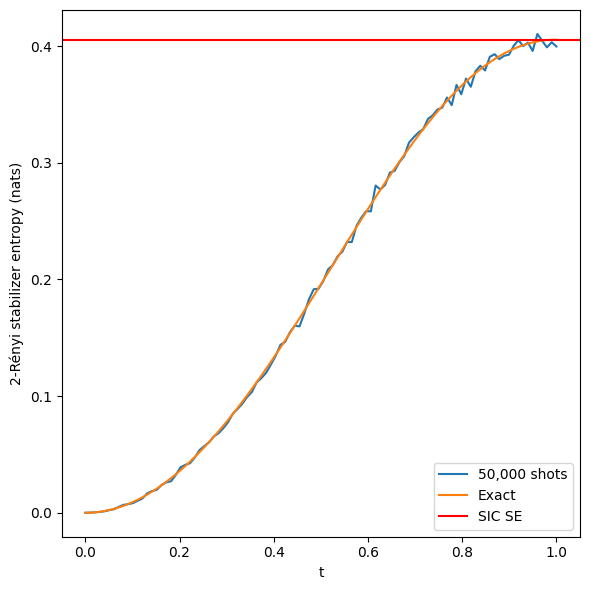

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(T, magic_t, label=f"{n_shots:,} shots")
ax.plot(T, exact_magic_t, label="Exact")
ax.axhline(max_magic, label="SIC SE", color="red")
ax.set(xlabel="t", ylabel=f"{alpha}-Rényi stabilizer entropy (nats)")
ax.legend()
fig.tight_layout()
fig.savefig(image_dir / f"{alpha}renyi_se.pdf")
plt.show()

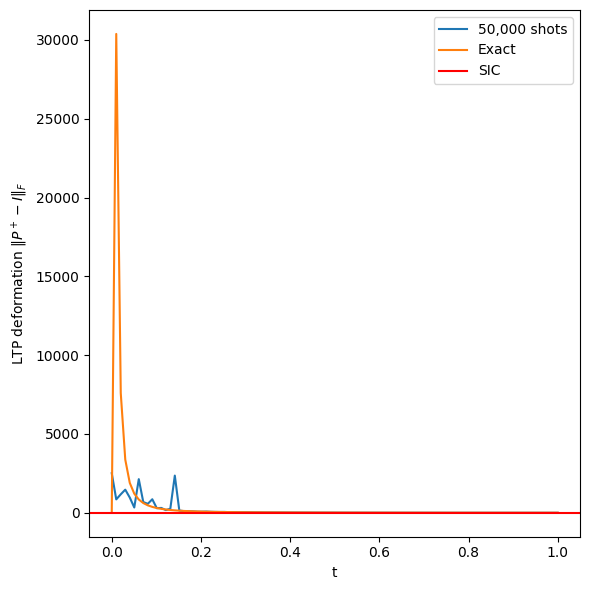

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(T, quantumness_t, label=f"{n_shots:,} shots")
ax.plot(T, exact_quantumness_t, label="Exact")
ax.axhline(sic_quantumness, label="SIC", color="red")
ax.set(xlabel="t", ylabel=r"LTP deformation $\|P^+-I\|_F$")
ax.legend()
fig.tight_layout()
fig.savefig(image_dir / "quantumness.pdf")
plt.show()

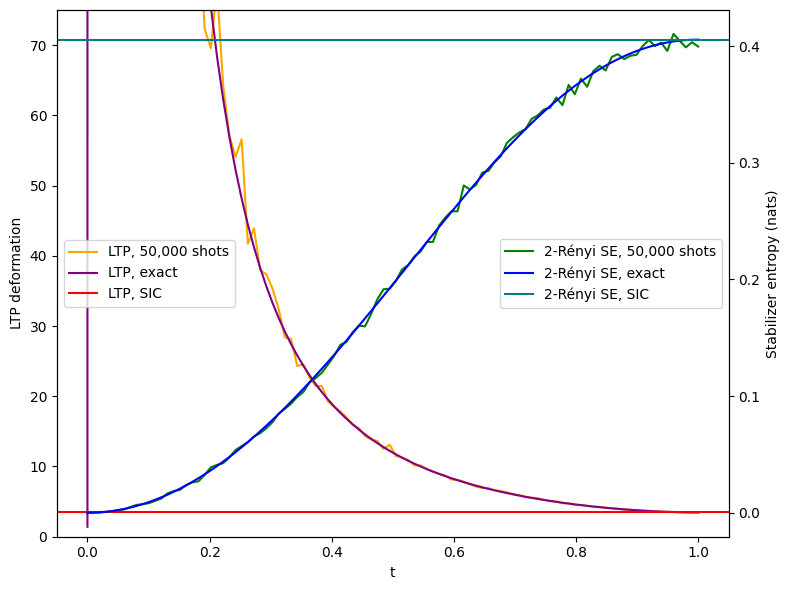

In [10]:
log = False
fig, ax = plt.subplots(figsize=(8, 6))
transform = np.log if log else np.asarray
ax.plot(T, transform(quantumness_t), label=f"LTP, {n_shots:,} shots", color="orange")
ax.plot(T, transform(exact_quantumness_t), label="LTP, exact", color="purple")
ax.axhline(transform(sic_quantumness), label="LTP, SIC", color="red")
# Retain the original display window; the full curves remain in the arrays.
ax.set(xlabel="t", ylabel="log LTP deformation" if log else "LTP deformation",
       ylim=(0, 8) if log else (0, 75))
ax2 = ax.twinx()
ax2.plot(T, magic_t, color="green", label=f"{alpha}-Rényi SE, {n_shots:,} shots")
ax2.plot(T, exact_magic_t, color="blue", label=f"{alpha}-Rényi SE, exact")
ax2.axhline(max_magic, label=f"{alpha}-Rényi SE, SIC", color="teal")
ax2.set_ylabel("Stabilizer entropy (nats)")
ax.legend(loc="center left")
ax2.legend(loc="center right")
fig.tight_layout()
fig.savefig(image_dir / f"{'log' if log else ''}both_order{alpha}.pdf")
plt.show()

## Several Rényi orders

Reuse the same reference matrices for each order. Separate panels keep the
entropy scales and SIC benchmarks readable without overwriting the order-2 arrays.

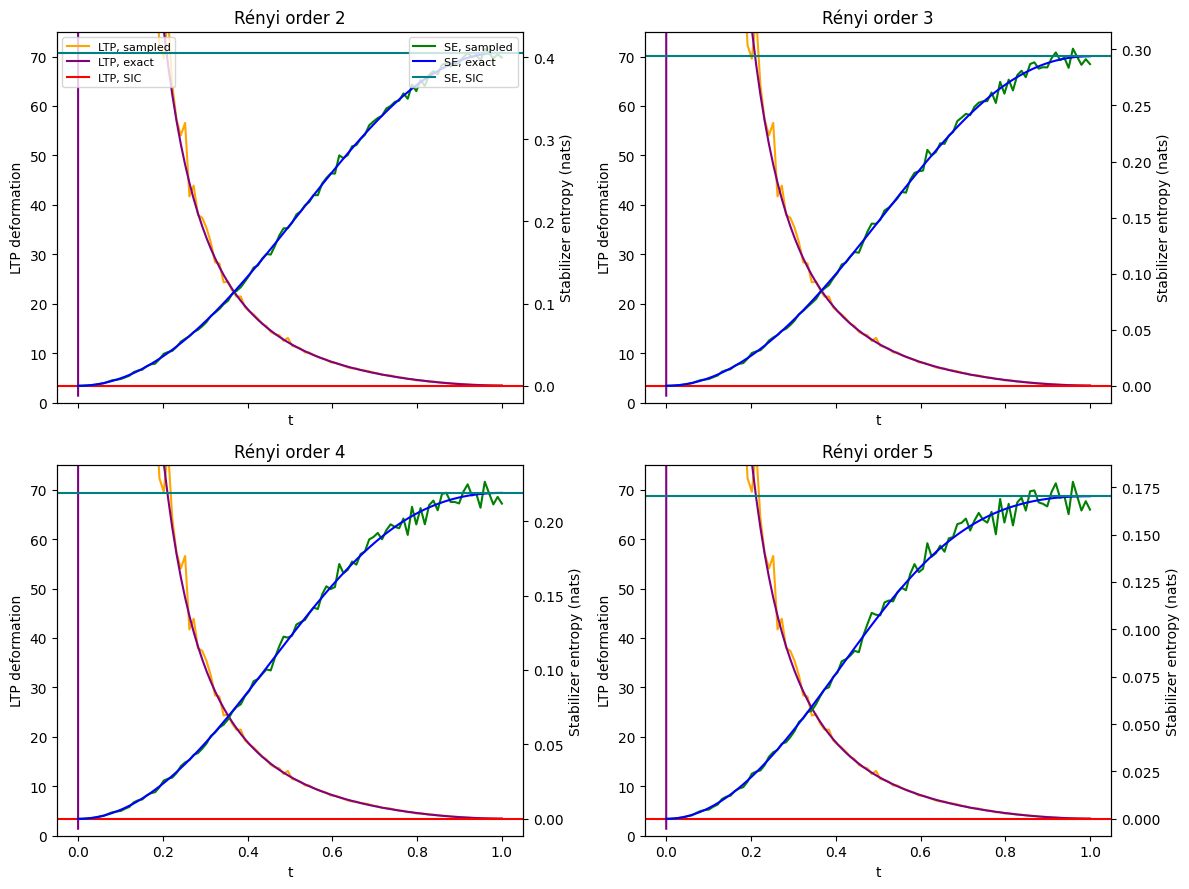

Saved experiment, results, and plots to /home/heyredhat/Documents/cirq_sic/artifacts/geodesic_ltp


In [11]:
magic_by_alpha = {order: calculate_magic(P_t, order) for order in alphas}
exact_magic_by_alpha = {order: calculate_magic(exact_P_t, order) for order in alphas}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
for ax, order in zip(axes.flat, alphas):
    ax.plot(T, quantumness_t, color="orange", label="LTP, sampled")
    ax.plot(T, exact_quantumness_t, color="purple", label="LTP, exact")
    ax.axhline(sic_quantumness, color="red", label="LTP, SIC")
    ax.set(xlabel="t", ylabel="LTP deformation", ylim=(0, 75), title=f"Rényi order {order}")
    ax2 = ax.twinx()
    ax2.plot(T, magic_by_alpha[order], color="green", label="SE, sampled")
    ax2.plot(T, exact_magic_by_alpha[order], color="blue", label="SE, exact")
    ax2.axhline(sic_entropy(order), color="teal", label="SE, SIC")
    ax2.set_ylabel("Stabilizer entropy (nats)")
    if order == alphas[0]:
        ax.legend(loc="upper left", fontsize=8)
        ax2.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(image_dir / "both_many_orders.pdf")
plt.show()
print(f"Saved experiment, results, and plots to {output_dir}")